In [1]:
import os
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

path = kagglehub.dataset_download("malikussaid/426k-pubchem-molecules-for-logp-prediction")
print("Path to dataset files:", path)

files = os.listdir(path)
print("Files in directory:", files)

csv_file_path = os.path.join(path, files[0])
df = pd.read_csv(csv_file_path)

display(df.head())
print(df.shape)

Path to dataset files: /kaggle/input/datasets/malikussaid/426k-pubchem-molecules-for-logp-prediction
Files in directory: ['Computed_Molecules.csv']


,InChIKey,SMILES,Original_InChI,logP_target,MolWt,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,NumAromaticRings,FractionCSP3,HeavyAtomCount
0,AFDNHPDPJGKQBF-UHFFFAOYSA-N,[H]c1c([H])c(C([H])([H])SC2=NC([H])([H])C([H])...,InChI=1S/C10H10N2O2S2/c13-12(14)9-3-1-8(2-4-9)...,2.6,254.336,55.50,0,5,3,1,0.3,16
1,RJLKWOXDUVZJLR-UHFFFAOYSA-N,[H]c1nc([H])c(S(=O)(=O)N([H])C([H])([H])c2c([H...,"InChI=1S/C10H10N2O2S2/c13-16(14,10-2-1-4-11-7-...",1.0,254.336,59.06,1,4,4,2,0.1,16
2,PWWYYMTYFYWPDY-UHFFFAOYSA-N,[H]c1nc([H])c(C([H])([H])N([H])S(=O)(=O)c2sc([...,"InChI=1S/C10H10N2O2S2/c13-16(14,10-4-2-6-15-10...",1.3,254.336,59.06,1,4,4,2,0.1,16
3,ARJMJQRFEJVSTC-UHFFFAOYSA-N,[H]c1nc(N([H])S(=O)(=O)C([H])([H])c2c([H])c([H...,"InChI=1S/C10H10N2O2S2/c13-16(14,12-10-11-6-7-1...",1.7,254.336,59.06,1,4,4,2,0.1,16
4,WHNUYUHLQKDZGQ-UHFFFAOYSA-N,[H]C([H])([H])C(=O)C([H])([H])Sc1nsc(SC([H])([...,InChI=1S/C10H10N2O2S3/c1-6(13)4-15-9-8(3-11)10...,1.9,286.403,70.82,0,7,8,1,0.4,17


(426850, 12)


In [2]:
print(df.info())
print()
print(df.describe())
print()
print(df.isna().sum())
print()
print(df.duplicated().sum())
print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426850 entries, 0 to 426849
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   InChIKey           426850 non-null  object 
 1   SMILES             426850 non-null  object 
 2   Original_InChI     426850 non-null  object 
 3   logP_target        426850 non-null  float64
 4   MolWt              426850 non-null  float64
 5   TPSA               426850 non-null  float64
 6   NumHDonors         426850 non-null  int64  
 7   NumHAcceptors      426850 non-null  int64  
 8   NumRotatableBonds  426850 non-null  int64  
 9   NumAromaticRings   426850 non-null  int64  
 10  FractionCSP3       426850 non-null  float64
 11  HeavyAtomCount     426850 non-null  int64  
dtypes: float64(4), int64(5), object(3)
memory usage: 39.1+ MB
None

         logP_target          MolWt           TPSA     NumHDonors  \
count  426850.000000  426850.000000  426850.000000  426850.000000

In [3]:
# 1. Remove duplicate molecules (same InChIKey = same molecule)
df = df.drop_duplicates(subset="InChIKey").reset_index(drop=True)

# 2. Keep only the columns the model will use
features = ["MolWt", "TPSA", "NumHDonors", "NumHAcceptors",
            "NumRotatableBonds", "NumAromaticRings",
            "FractionCSP3", "HeavyAtomCount"]
target = "logP_target"

data = df[features + [target]].copy()
print(data.shape)

(426837, 9)


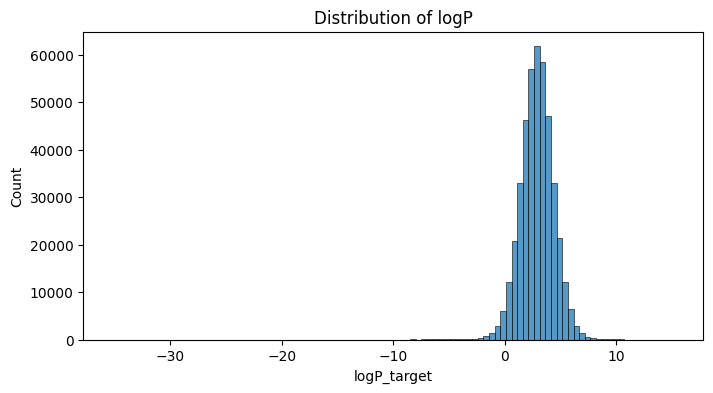

0.001   -4.7
0.010   -0.7
0.500    2.9
0.990    6.3
0.999    8.3
Name: logP_target, dtype: float64


In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(data[target], bins=100)
plt.title("Distribution of logP")
plt.show()

print(data[target].quantile([0.001, 0.01, 0.5, 0.99, 0.999]))

In [5]:
print("logP < -5 :", (data[target] < -5).sum())
print("logP > 10 :", (data[target] > 10).sum())
print("MolWt > 1000 :", (data["MolWt"] > 1000).sum())
print("HeavyAtomCount > 80 :", (data["HeavyAtomCount"] > 80).sum())
print("RotatableBonds > 30 :", (data["NumRotatableBonds"] > 30).sum())

logP < -5 : 364
logP > 10 : 62
MolWt > 1000 : 178
HeavyAtomCount > 80 : 175
RotatableBonds > 30 : 200


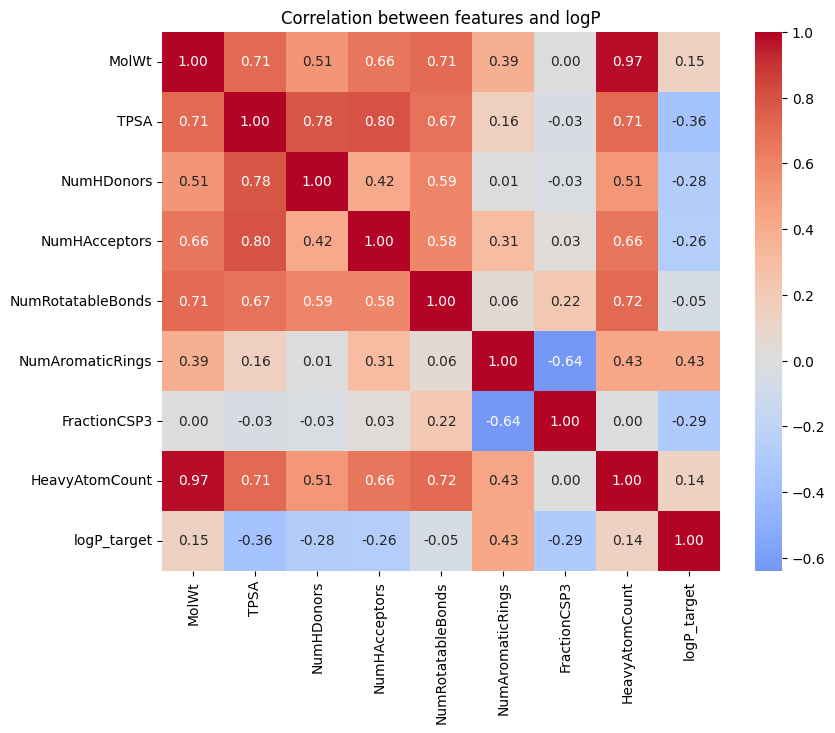

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between features and logP")
plt.show()

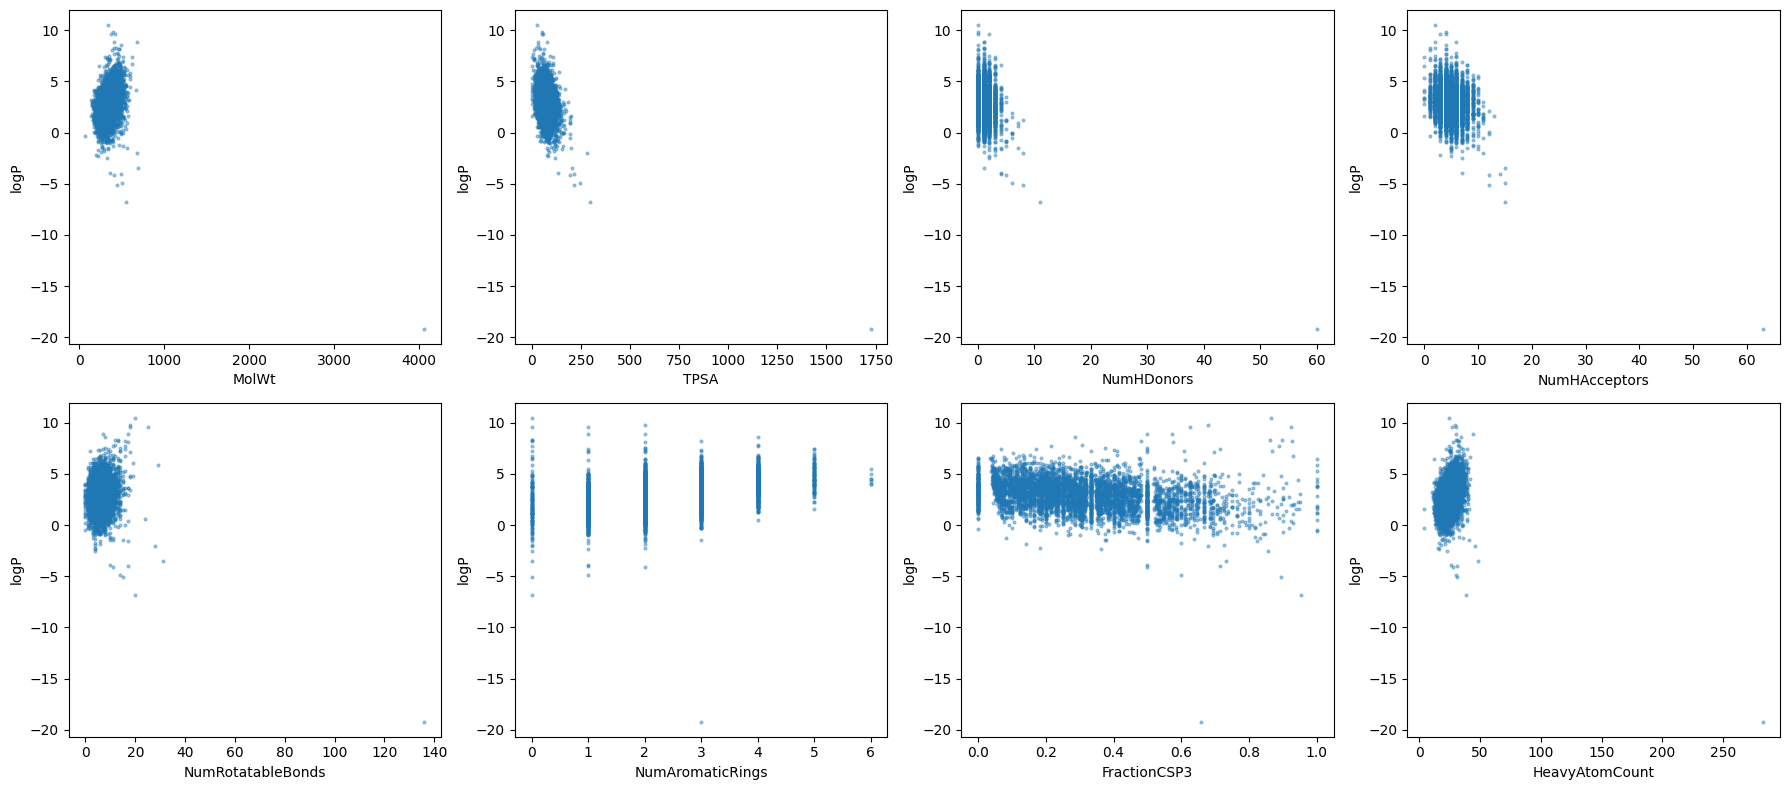

In [7]:
sample = data.sample(5000, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    ax.scatter(sample[col], sample[target], s=4, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("logP")
plt.tight_layout()
plt.show()

In [8]:
before = len(data)

data = data[
    (data[target].between(-5, 10)) &
    (data["MolWt"] <= 1000) &
    (data["HeavyAtomCount"] <= 80) &
    (data["NumRotatableBonds"] <= 30)
].reset_index(drop=True)

print("Rows before:", before)
print("Rows after :", len(data))
print("Removed    :", before - len(data))

Rows before: 426837
Rows after : 426358
Removed    : 479


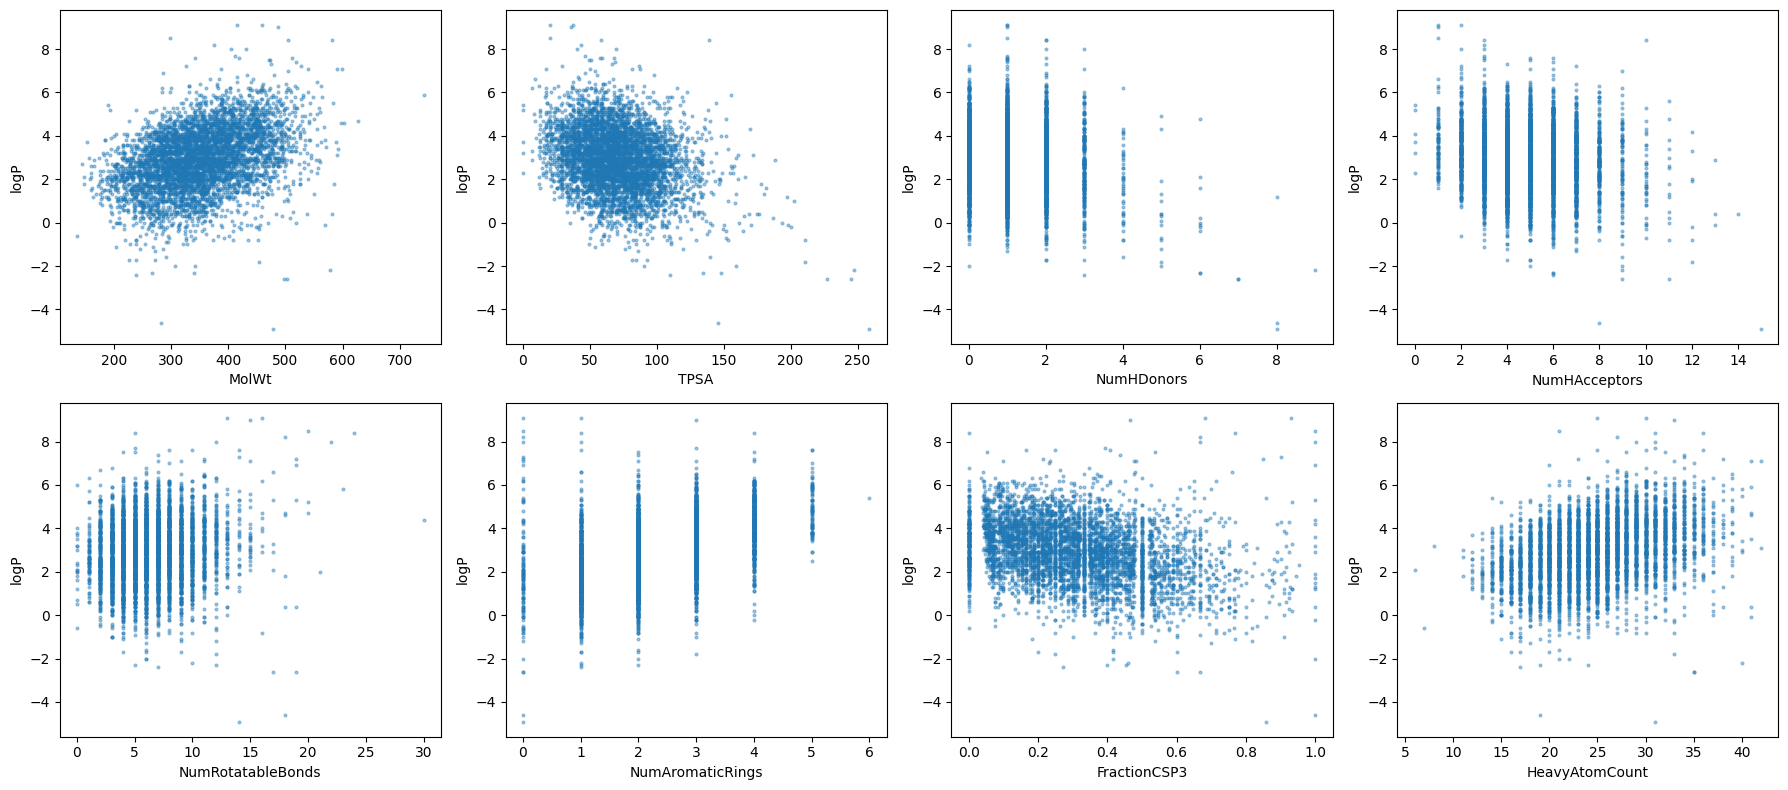

In [9]:
sample = data.sample(5000, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    ax.scatter(sample[col], sample[target], s=4, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("logP")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

X = data[features]
y = data[target]

# First: split off 20% for the final test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Then: split the remaining 80% into train (60% of total) and validation (20% of total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42
)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

Train: (255814, 8)
Val  : (85272, 8)
Test : (85272, 8)


In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:20s} RMSE={rmse:.3f}  MAE={mae:.3f}  R2={r2:.3f}")
    return rmse, mae, r2

In [12]:
mean_pred = np.full(len(y_val), y_train.mean())
evaluate("Mean guess", y_val, mean_pred)

Mean guess           RMSE=1.452  MAE=1.132  R2=-0.000


(np.float64(1.4519422365887729), 1.1315540282753476, -1.014384380937372e-07)

In [13]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)
evaluate("Linear Regression", y_val, lin.predict(X_val))

Linear Regression    RMSE=0.922  MAE=0.709  R2=0.596


(np.float64(0.9223427777586319), 0.7086518326881893, 0.5964604837125823)

In [14]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42
)
rf.fit(X_train, y_train)
evaluate("Random Forest", y_val, rf.predict(X_val))

Random Forest        RMSE=0.740  MAE=0.553  R2=0.740


(np.float64(0.7397076006220331), 0.5526691235328104, 0.7404497039771163)

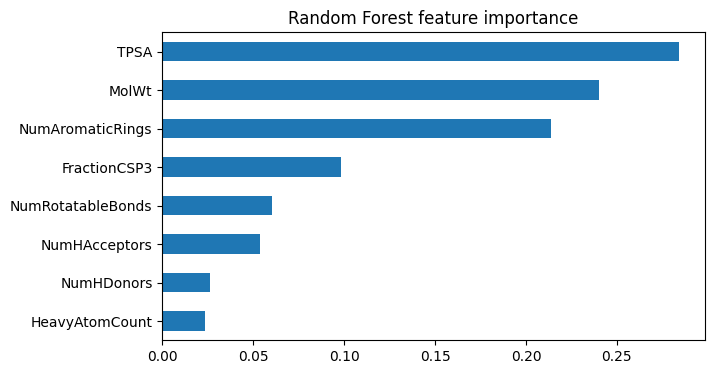

TPSA                 0.284073
MolWt                0.240214
NumAromaticRings     0.213712
FractionCSP3         0.098191
NumRotatableBonds    0.060184
NumHAcceptors        0.053830
NumHDonors           0.026341
HeavyAtomCount       0.023455
dtype: float64


In [15]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Random Forest feature importance")
plt.show()
print(imp.sort_values(ascending=False))

The forest’s built-in importance is known to favour continuous features (TPSA, MolWt) over small-count ones (H-donors). So we cross-check it with a permutation importance method. 

Permutation importance : take a trained model, shuffle one column so it becomes random noise, and see how much the error gets worse. If shuffling TPSA makes the model much worse, TPSA was important. This is measured on validation data, so it shows what actually helps on unseen molecules.

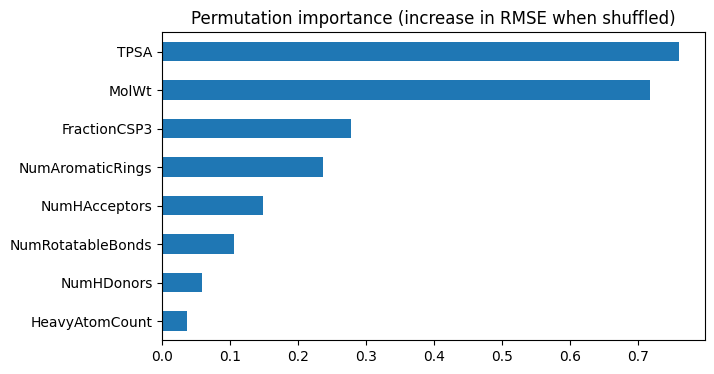

TPSA                 0.760803
MolWt                0.718079
FractionCSP3         0.277753
NumAromaticRings     0.237424
NumHAcceptors        0.148266
NumRotatableBonds    0.105985
NumHDonors           0.058661
HeavyAtomCount       0.036572
dtype: float64


In [16]:
from sklearn.inspection import permutation_importance

# Use 20k validation rows to keep it fast
idx = X_val.sample(20000, random_state=42).index

pi = permutation_importance(
    rf, X_val.loc[idx], y_val.loc[idx],
    n_repeats=5, random_state=42, n_jobs=-1,
    scoring="neg_root_mean_squared_error"
)

pi_series = pd.Series(pi.importances_mean, index=features).sort_values()
pi_series.plot(kind="barh", figsize=(7, 4),
               title="Permutation importance (increase in RMSE when shuffled)")
plt.show()
print(pi_series.sort_values(ascending=False))

In [17]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=50,
    n_jobs=-1,
    random_state=42,
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=100
)

print("Best number of trees:", xgb_model.best_iteration)
_ = evaluate("XGBoost", y_val, xgb_model.predict(X_val))

[0]	validation_0-rmse:1.41680
[100]	validation_0-rmse:0.83992
[200]	validation_0-rmse:0.81969
[300]	validation_0-rmse:0.80945
[400]	validation_0-rmse:0.80174
[500]	validation_0-rmse:0.79506
[600]	validation_0-rmse:0.78921
[700]	validation_0-rmse:0.78439
[800]	validation_0-rmse:0.78026
[900]	validation_0-rmse:0.77672
[1000]	validation_0-rmse:0.77330
[1100]	validation_0-rmse:0.77014
[1200]	validation_0-rmse:0.76760
[1300]	validation_0-rmse:0.76512
[1400]	validation_0-rmse:0.76264
[1500]	validation_0-rmse:0.76034
[1600]	validation_0-rmse:0.75829
[1700]	validation_0-rmse:0.75619
[1800]	validation_0-rmse:0.75407
[1900]	validation_0-rmse:0.75225
[1999]	validation_0-rmse:0.75053
Best number of trees: 1999
XGBoost              RMSE=0.751  MAE=0.573  R2=0.733


In [18]:
import time
from sklearn.model_selection import ParameterSampler

xgb_space = {
    "max_depth": [6, 8, 10, 12],
    "learning_rate": [0.05, 0.1],
    "min_child_weight": [1, 5, 10],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_lambda": [1, 5, 10],
}

xgb_results = []
for i, params in enumerate(ParameterSampler(xgb_space, n_iter=10, random_state=42)):
    t0 = time.time()
    m = xgb.XGBRegressor(
        n_estimators=3000, early_stopping_rounds=50,
        n_jobs=-1, random_state=42, **params
    )
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    rmse = np.sqrt(mean_squared_error(y_val, m.predict(X_val)))
    xgb_results.append({**params, "trees": m.best_iteration, "val_rmse": rmse})
    print(f"{i+1}/10  rmse={rmse:.4f}  trees={m.best_iteration}  ({time.time()-t0:.0f}s)")

xgb_df = pd.DataFrame(xgb_results).sort_values("val_rmse")
xgb_df

1/10  rmse=0.6802  trees=1076  (36s)
2/10  rmse=0.7400  trees=2999  (38s)
3/10  rmse=0.6899  trees=2999  (48s)
4/10  rmse=0.6880  trees=1341  (44s)
5/10  rmse=0.6880  trees=2999  (72s)
6/10  rmse=0.7393  trees=2999  (42s)
7/10  rmse=0.6901  trees=1866  (44s)
8/10  rmse=0.7259  trees=2999  (39s)
9/10  rmse=0.7447  trees=2999  (42s)
10/10  rmse=0.6793  trees=2999  (75s)


,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,colsample_bytree,trees,val_rmse
9,0.8,10,1,10,0.05,0.8,2999,0.679299
0,0.9,5,5,12,0.10,1.0,1076,0.680223
3,0.7,10,10,12,0.10,0.8,1341,0.688035
4,0.7,1,10,10,0.05,0.7,2999,0.688049
2,0.9,10,10,8,0.10,1.0,2999,0.689878
6,0.8,1,10,10,0.10,0.7,1866,0.690081
7,0.9,5,10,6,0.10,0.7,2999,0.725859
5,0.8,10,5,6,0.05,1.0,2999,0.739283
1,0.8,5,1,6,0.05,0.8,2999,0.740018
8,0.7,10,5,6,0.05,0.8,2999,0.744736


In [19]:
rf_space = {
    "n_estimators": [100, 200],
    "min_samples_leaf": [1, 2, 3, 5],
    "max_features": [0.5, 0.75, 1.0],
    "max_depth": [None, 20, 30],
}

X_small = X_train.sample(100000, random_state=42)
y_small = y_train.loc[X_small.index]

rf_results = []
for i, params in enumerate(ParameterSampler(rf_space, n_iter=6, random_state=42)):
    t0 = time.time()
    m = RandomForestRegressor(n_jobs=-1, random_state=42, **params)
    m.fit(X_small, y_small)
    rmse = np.sqrt(mean_squared_error(y_val, m.predict(X_val)))
    rf_results.append({**params, "val_rmse": rmse})
    print(f"{i+1}/6  rmse={rmse:.4f}  ({time.time()-t0:.0f}s)")

rf_df = pd.DataFrame(rf_results).sort_values("val_rmse")
rf_df

1/6  rmse=0.7799  (10s)
2/6  rmse=0.7896  (13s)
3/6  rmse=0.7791  (21s)
4/6  rmse=0.7695  (15s)
5/6  rmse=0.7822  (10s)
6/6  rmse=0.7738  (12s)


,n_estimators,min_samples_leaf,max_features,max_depth,val_rmse
3,100,1,0.50,NaN,0.769504
5,100,2,0.50,30.0,0.773793
2,100,2,1.00,NaN,0.779128
0,100,3,0.50,NaN,0.779914
4,100,3,0.50,20.0,0.782238
1,100,5,0.75,30.0,0.789603


In [20]:
rf_best = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=1, max_features=0.5,
    max_depth=None, n_jobs=-1, random_state=42
)
rf_best.fit(X_train, y_train)
_ = evaluate("RF tuned", y_val, rf_best.predict(X_val))

RF tuned             RMSE=0.704  MAE=0.512  R2=0.765


In [21]:
xgb_best = xgb.XGBRegressor(
    n_estimators=3000, early_stopping_rounds=50,
    learning_rate=0.1, max_depth=12, min_child_weight=5,
    subsample=0.9, colsample_bytree=1.0, reg_lambda=5,
    n_jobs=-1, random_state=42
)
xgb_best.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("Best number of trees:", xgb_best.best_iteration)
_ = evaluate("XGBoost tuned", y_val, xgb_best.predict(X_val))

Best number of trees: 1076
XGBoost tuned        RMSE=0.680  MAE=0.493  R2=0.781


In [22]:
models = {
    "Mean guess": np.full(len(y_val), y_train.mean()),
    "Linear Regression": lin.predict(X_val),
    "Random Forest (default)": rf.predict(X_val),
    "Random Forest (tuned)": rf_best.predict(X_val),
    "XGBoost (default)": xgb_model.predict(X_val),
    "XGBoost (tuned)": xgb_best.predict(X_val),
}

rows = []
for name, pred in models.items():
    rows.append({
        "model": name,
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "MAE": mean_absolute_error(y_val, pred),
        "R2": r2_score(y_val, pred),
    })

comparison = pd.DataFrame(rows).sort_values("RMSE").round(3)
comparison

,model,RMSE,MAE,R2
5,XGBoost (tuned),0.680,0.493,0.781
3,Random Forest (tuned),0.704,0.512,0.765
2,Random Forest (default),0.740,0.553,0.740
4,XGBoost (default),0.751,0.573,0.733
1,Linear Regression,0.922,0.709,0.596
0,Mean guess,1.452,1.132,-0.000


In [23]:
test_pred = xgb_best.predict(X_test)
_ = evaluate("XGBoost tuned (TEST)", y_test, test_pred)

XGBoost tuned (TEST) RMSE=0.679  MAE=0.493  R2=0.777


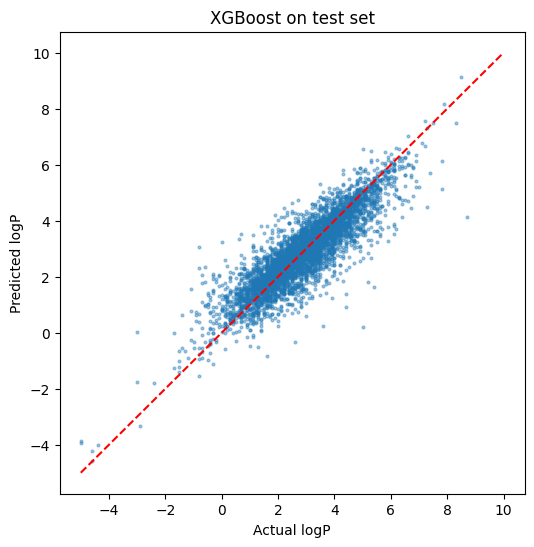

In [24]:
s = np.random.RandomState(42).choice(len(y_test), 5000, replace=False)

plt.figure(figsize=(6, 6))
plt.scatter(y_test.iloc[s], test_pred[s], s=4, alpha=0.4)
plt.plot([-5, 10], [-5, 10], "r--")
plt.xlabel("Actual logP")
plt.ylabel("Predicted logP")
plt.title("XGBoost on test set")
plt.show()

In [25]:
import joblib

xgb_best.save_model("xgb_model.json")
joblib.dump(rf_best, "rf_model.joblib")

print("XGBoost file:", round(os.path.getsize("xgb_model.json") / 1e6, 1), "MB")
print("RF file     :", round(os.path.getsize("rf_model.joblib") / 1e6, 1), "MB")

XGBoost file: 138.5 MB
RF file     : 1893.6 MB


In [26]:
%%writefile train.py
"""Train the final XGBoost model that predicts logP from 8 molecular descriptors."""
import argparse
import json

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

FEATURES = [
    "MolWt", "TPSA", "NumHDonors", "NumHAcceptors",
    "NumRotatableBonds", "NumAromaticRings", "FractionCSP3", "HeavyAtomCount",
]
TARGET = "logP_target"


def load_and_clean(path):
    df = pd.read_csv(path, usecols=["InChIKey"] + FEATURES + [TARGET])
    df = df.drop_duplicates(subset="InChIKey").reset_index(drop=True)
    # Keep only normal drug-like molecules (removes extreme outliers)
    df = df[
        df[TARGET].between(-5, 10)
        & (df["MolWt"] <= 1000)
        & (df["HeavyAtomCount"] <= 80)
        & (df["NumRotatableBonds"] <= 30)
    ].reset_index(drop=True)
    return df[FEATURES + [TARGET]]


def evaluate(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
    }


def main(data_path, model_path, metrics_path):
    data = load_and_clean(data_path)
    print("Clean rows:", len(data))

    X, y = data[FEATURES], data[TARGET]
    X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

    # Best settings found by hyperparameter tuning in the notebook
    model = xgb.XGBRegressor(
        n_estimators=3000, early_stopping_rounds=50,
        learning_rate=0.1, max_depth=12, min_child_weight=5,
        subsample=0.9, colsample_bytree=1.0, reg_lambda=5,
        n_jobs=-1, random_state=42,
    )
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    print("Best number of trees:", model.best_iteration)

    metrics = {
        "validation": evaluate(y_val, model.predict(X_val)),
        "test": evaluate(y_test, model.predict(X_test)),
        "best_iteration": int(model.best_iteration),
        "features": FEATURES,
    }
    print(json.dumps(metrics, indent=2))

    model.save_model(model_path)
    with open(metrics_path, "w") as f:
        json.dump(metrics, f, indent=2)
    print("Saved model to", model_path)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", required=True, help="path to the CSV file")
    parser.add_argument("--model-out", default="model.ubj")
    parser.add_argument("--metrics-out", default="metrics.json")
    args = parser.parse_args()
    main(args.data, args.model_out, args.metrics_out)

Writing train.py


In [31]:
!python train.py --data "/kaggle/input/datasets/malikussaid/426k-pubchem-molecules-for-logp-prediction/Computed_Molecules.csv" --model-out model.ubj --metrics-out metrics.json

Clean rows: 426358
Best number of trees: 1076
{
  "validation": {
    "rmse": 0.6802233228398948,
    "mae": 0.4926766430915721,
    "r2": 0.7805152233259456
  },
  "test": {
    "rmse": 0.6791584224628994,
    "mae": 0.4928843121408846,
    "r2": 0.7774359046559709
  },
  "best_iteration": 1076,
  "features": [
    "MolWt",
    "TPSA",
    "NumHDonors",
    "NumHAcceptors",
    "NumRotatableBonds",
    "NumAromaticRings",
    "FractionCSP3",
    "HeavyAtomCount"
  ]
}
Saved model to model.ubj


In [32]:
print(round(os.path.getsize("model.ubj") / 1e6, 1), "MB")

85.6 MB


In [33]:
%%writefile predict.py
"""FastAPI service: predict logP from 8 molecular descriptors."""
import os

import pandas as pd
import xgboost as xgb
from fastapi import FastAPI
from pydantic import BaseModel, Field

FEATURES = [
    "MolWt", "TPSA", "NumHDonors", "NumHAcceptors",
    "NumRotatableBonds", "NumAromaticRings", "FractionCSP3", "HeavyAtomCount",
]
MODEL_PATH = os.getenv("MODEL_PATH", "model.ubj")

# Load the model once when the service starts (not on every request)
model = xgb.XGBRegressor()
model.load_model(MODEL_PATH)

app = FastAPI(title="logP Predictor", version="1.0")


class Molecule(BaseModel):
    # Limits match the data the model was trained on (drug-like molecules)
    MolWt: float = Field(..., gt=0, le=1000, description="Molecular weight (Da)")
    TPSA: float = Field(..., ge=0, description="Topological polar surface area (Å²)")
    NumHDonors: int = Field(..., ge=0, description="H-bond donors")
    NumHAcceptors: int = Field(..., ge=0, description="H-bond acceptors")
    NumRotatableBonds: int = Field(..., ge=0, le=30, description="Rotatable bonds")
    NumAromaticRings: int = Field(..., ge=0, description="Aromatic rings")
    FractionCSP3: float = Field(..., ge=0, le=1, description="Fraction of sp3 carbons")
    HeavyAtomCount: int = Field(..., ge=1, le=80, description="Non-hydrogen atoms")


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict")
def predict(mol: Molecule):
    row = pd.DataFrame([mol.model_dump()])[FEATURES]  # keep the column order the model expects
    logp = float(model.predict(row)[0])
    return {
        "predicted_logp": round(logp, 2),
        "lipinski_logp_ok": logp <= 5,  # Lipinski's rule: logP should be 5 or less
    }

Writing predict.py


In [34]:
!pip install -q fastapi httpx uvicorn

In [35]:
from fastapi.testclient import TestClient
import predict

client = TestClient(predict.app)

# Aspirin
aspirin = {
    "MolWt": 180.16, "TPSA": 63.6, "NumHDonors": 1, "NumHAcceptors": 3,
    "NumRotatableBonds": 2, "NumAromaticRings": 1,
    "FractionCSP3": 0.111, "HeavyAtomCount": 13,
}

print(client.get("/health").json())
print(client.post("/predict", json=aspirin).json())

# A bad input: negative molecular weight
bad = {**aspirin, "MolWt": -5}
r = client.post("/predict", json=bad)
print(r.status_code)

{'status': 'ok'}
{'predicted_logp': 1.9, 'lipinski_logp_ok': True}
422


In [36]:
import xgboost, fastapi, pandas, pydantic, uvicorn, sklearn
for m in [xgboost, fastapi, pandas, pydantic, uvicorn, sklearn]:
    print(m.__name__, m.__version__)

xgboost 3.4.1
fastapi 0.141.1
pandas 2.3.3
pydantic 2.14.1
uvicorn 0.54.0
sklearn 1.6.1
